In [1]:
import torch
import torch.nn as nn
from torchvision.models import resnet18, ResNet18_Weights

weights = ResNet18_Weights.DEFAULT   # 가장 좋은 사전학습 가중치
print(weights.transforms())          # 이 모델이 원하는 사진 손질법

ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)


In [2]:
from torchvision import transforms as T
from torchvision.datasets import OxfordIIITPet

MEAN = [0.485, 0.456, 0.406]   # 2-1에서 메모한 숫자
STD = [0.229, 0.224, 0.225]

train_tf = T.Compose([
    T.RandomResizedCrop(224, scale=(0.7, 1.0)),   # 무작위로 오려서 정사각형으로
    T.RandomHorizontalFlip(p=0.5),                 # 반반 확률로 좌우 뒤집기
    T.ToTensor(),                                   # 사진 → 숫자 상자(텐서)
    T.Normalize(MEAN, STD),                         # 색 맞추기
])

test_tf = T.Compose([
    T.Resize(256),                                  # 짧은 쪽을 줄이기
    T.CenterCrop(224),                              # 가운데 오리기
    T.ToTensor(),
    T.Normalize(MEAN, STD),
])

In [3]:
sample = OxfordIIITPet(root="../data", split="trainval",
                       target_types="binary-category", transform=train_tf)
x, label = sample[0]
assert x.shape == (3, 224, 224), f"(3, 224, 224)여야 해요. 지금: {tuple(x.shape)}"
print("통과! 사진 한 장 →", tuple(x.shape))

통과! 사진 한 장 → (3, 224, 224)


In [4]:
from torch.utils.data import Subset

full_train = OxfordIIITPet(root="../data", split="trainval", target_types="binary-category", transform=train_tf)
full_val = OxfordIIITPet(root="../data", split="trainval", target_types="binary-category", transform=test_tf)
test_set = OxfordIIITPet(root="../data", split="test", target_types="binary-category", transform=test_tf)

g = torch.Generator().manual_seed(42)                 # 매번 똑같이 섞이도록 고정
idx = torch.randperm(len(full_train), generator=g).tolist()   # 사진 번호 섞기
n_train = int(len(idx) * 0.8)                        # 연습 문제 개수

train_set = Subset(full_train, idx[:n_train])         # 앞부분
val_set = Subset(full_val, idx[n_train:])             # 나머지

print("연습:", len(train_set), "/ 모의고사:", len(val_set), "/ 수능:", len(test_set))

연습: 2944 / 모의고사: 736 / 수능: 3669


In [5]:
assert len(train_set) == 2944 and len(val_set) == 736, "2944 / 736이 나와야 해요"
assert not set(train_set.indices) & set(val_set.indices), "연습과 모의고사에 같은 사진이 있으면 안 돼요"
print("통과!")

통과!


In [6]:
from torch.utils.data import DataLoader

train_loader = DataLoader(train_set, batch_size=32, shuffle=True)
val_loader = DataLoader(val_set, batch_size=32, shuffle=False)
test_loader = DataLoader(test_set, batch_size=32, shuffle=False)

xb, yb = next(iter(train_loader))     # 한 묶음만 꺼내 보기
print(xb.shape, yb[:8])

torch.Size([32, 3, 224, 224]) tensor([0, 1, 0, 1, 0, 1, 1, 0])


In [7]:
assert xb.shape == (32, 3, 224, 224), f"지금: {tuple(xb.shape)}"
print("통과! 사진 32장 묶음 →", tuple(xb.shape))

통과! 사진 32장 묶음 → (32, 3, 224, 224)


In [8]:
model = resnet18(weights=weights).eval()      # 사전학습 모델 불러오기 ("지금은 시험 시간")
imagenet_names = weights.meta["categories"]   # ImageNet 1000종류 이름표

raw_test = OxfordIIITPet(root="../data", split="test", target_types="binary-category")   # 손질 전 사진
for i in [0, 1000, 2000]:
    img, label = raw_test[i]
    x = weights.transforms()(img).unsqueeze(0)   # 손질 + 한 장짜리 묶음으로 (1, 3, 224, 224)
    with torch.no_grad():
        prob = model(x).softmax(dim=1)[0]        # 1000종류 각각의 확률
    top = prob.topk(3)                        # 확률 높은 순서로 3개
    guesses = [f"{imagenet_names[j]} {p:.0%}" for p, j in zip(top.values, top.indices)]
    print(["고양이", "개"][label], "→", guesses)

고양이 → ['Egyptian cat 70%', 'tabby 8%', 'lynx 5%']
개 → ['Chihuahua 98%', 'French bulldog 1%', 'muzzle 0%']
고양이 → ['tabby 53%', 'lynx 18%', 'tiger cat 17%']


In [9]:
print("바꾸기 전:", model.fc)

model.fc = nn.Linear(512, 2)    # 새 마지막 층 (들어오는 수, 나가는 수)

print("바꾼 후:", model.fc)

바꾸기 전: Linear(in_features=512, out_features=1000, bias=True)
바꾼 후: Linear(in_features=512, out_features=2, bias=True)


In [10]:
out = model(xb[:4])                  # 4-2에서 꺼낸 사진 중 4장
assert out.shape == (4, 2), f"사진마다 점수 2개가 나와야 해요. 지금: {tuple(out.shape)}"
print("통과! 이제 개/고양이 두 가지로만 대답해요", tuple(out.shape))

통과! 이제 개/고양이 두 가지로만 대답해요 (4, 2)


In [11]:
device = "cuda" if torch.cuda.is_available() else "cpu"

model = resnet18(weights=weights)       # 사전학습 모델을 깨끗하게 다시 불러오기
for p in model.parameters():
    p.requires_grad = False              # 앞부분 전부 얼리기

model.fc = nn.Linear(512, 2)            # 새 층은 얼리기 "뒤에" 끼워야 학습돼요
model = model.to(device)

n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
n_all = sum(p.numel() for p in model.parameters())
print(f"학습할 값: {n_train:,}개 / 전체: {n_all:,}개")

학습할 값: 1,026개 / 전체: 11,177,538개


In [12]:
assert n_train == 512 * 2 + 2, "마지막 층(가중치 1024 + 편향 2)만 학습해야 해요"
print("통과! 학습할 값은 마지막 층의", n_train, "개뿐이에요")

통과! 학습할 값은 마지막 층의 1026 개뿐이에요


In [16]:
def evaluate(loader):
    model.eval()                             # "지금은 시험 시간"
    correct, total = 0, 0
    with torch.no_grad():                    # 채점할 땐 기울기 계산 안 함
        for x, y in loader:
            pred = model(x.to(device)).argmax(dim=1)   # 두 점수 중 큰 쪽의 번호
            correct += (pred == y.to(device)).sum().item()
            total += len(y)
    return correct / total

print(f"학습 전 모의고사 정확도: {evaluate(val_loader):.1%}")

학습 전 모의고사 정확도: 36.7%


In [17]:
optim = torch.optim.AdamW(model.fc.parameters(), lr=1e-3)   # 마지막 층만 고치기
loss_fn = nn.CrossEntropyLoss()
best_acc = 0

for epoch in range(3):
    model.train()                          # "지금은 공부 시간"
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        optim.zero_grad()
        loss = loss_fn(model(x), y)
        loss.backward()
        optim.step()

    val_acc = evaluate(val_loader)         # 바퀴마다 모의고사
    print(f"{epoch + 1}바퀴: loss {loss.item():.3f}, 모의고사 {val_acc:.1%}")

    if val_acc > best_acc:              # 최고 기록을 넘었을 때만
        best_acc = val_acc
        torch.save(model.state_dict(), "best.pth")
        print("  ↳ 최고 기록! best.pth 저장")

1바퀴: loss 0.153, 모의고사 96.5%
  ↳ 최고 기록! best.pth 저장
2바퀴: loss 0.077, 모의고사 98.2%
  ↳ 최고 기록! best.pth 저장
3바퀴: loss 0.140, 모의고사 98.4%
  ↳ 최고 기록! best.pth 저장


In [18]:
assert best_acc > 0.9, "모의고사 90%를 넘지 못했어요. 1-1에서 얼리기·새 층 순서를 확인해 보세요"
print(f"통과! 최고 모의고사 점수 {best_acc:.1%}")

통과! 최고 모의고사 점수 98.4%


In [19]:
model.load_state_dict(torch.load("best.pth"))   # 최고 기록 불러오기
test_acc = evaluate(test_loader)
print(f"수능 정확도: {test_acc:.1%}  (기준: 무조건 개 67.7%)")

수능 정확도: 98.0%  (기준: 무조건 개 67.7%)


In [20]:
assert test_acc > 0.677, "기준선도 못 넘었어요"
print("통과! 기준선보다", f"{(test_acc - 0.677) * 100:.1f}%p 높아요")

통과! 기준선보다 30.3%p 높아요


고양이: 1183장 중 정확도 95.4%
개: 2486장 중 정확도 99.2%


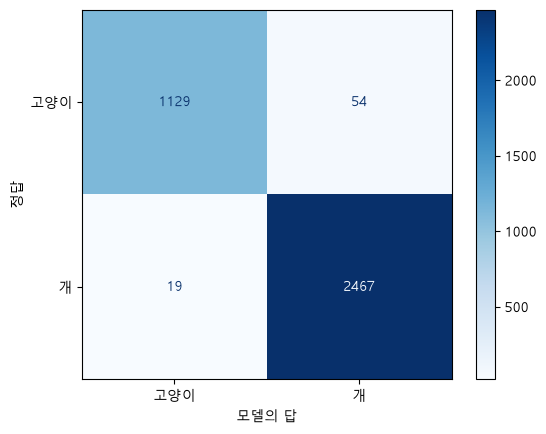

In [21]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "Malgun Gothic"

# 시험용 전체의 예측과 정답 모으기
model.eval()
preds, labels = [], []
with torch.no_grad():
    for x, y in test_loader:
        preds.append(model(x.to(device)).argmax(dim=1).cpu())
        labels.append(y)
preds, labels = torch.cat(preds), torch.cat(labels)

# 고양이(0), 개(1) 따로 채점
for c, name in [(0, "고양이"), (1, "개")]:
    mask = labels == c                       # 정답이 이 동물인 사진만 고르기
    acc = (preds[mask] == c).float().mean().item()
    print(f"{name}: {mask.sum().item()}장 중 정확도 {acc:.1%}")

cm = confusion_matrix(labels, preds)
ConfusionMatrixDisplay(cm, display_labels=["고양이", "개"]).plot(cmap="Blues")
plt.xlabel("모델의 답"); plt.ylabel("정답")
plt.show()

틀린 사진: 73 장


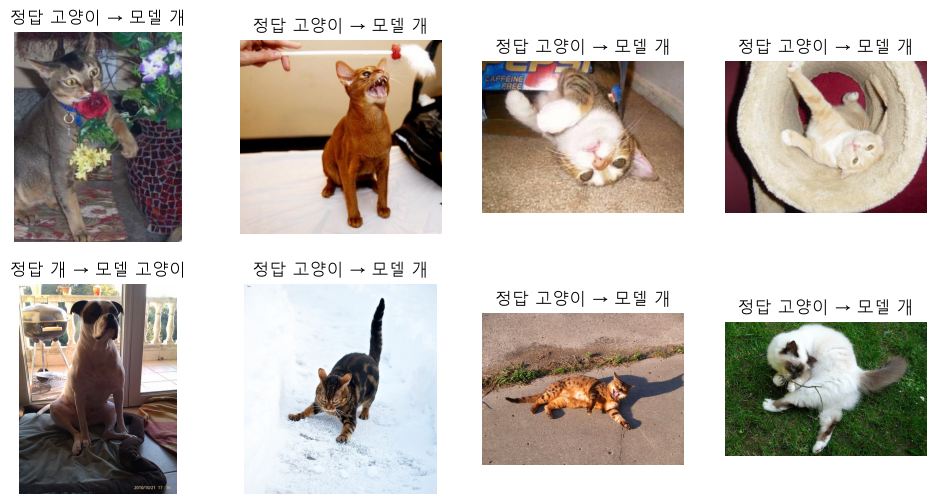

In [ ]:
wrong = (preds != labels).nonzero().flatten().tolist()   # 예측과 정답이 다른 사진 번호
print("틀린 사진:", len(wrong), "장")

names = ["고양이", "개"]
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, i in zip(axes.flat, wrong[:8]):
    img, label = raw_test[i]                 # Day 2에서 만든 손질 전 사진
    ax.imshow(img)
    ax.set_title(f"정답 {names[label]} → 모델 {names[preds[i]]}")
    ax.axis("off")
plt.show()

In [30]:
breed_test = OxfordIIITPet(root="../data", split="test", target_types="category") 

print(len(breed_test))          # raw_test와 같은 3669장이어야 해요
print(breed_test.classes[:5])   # 품종 이름 목록 앞 5개

3669
['Abyssinian', 'American Bulldog', 'American Pit Bull Terrier', 'Basset Hound', 'Beagle']


In [31]:
i = wrong[0]                         # 첫 번째로 틀린 사진 번호
img, breed_label = breed_test[i]  # 그 번호의 사진과 품종 번호
print(breed_label, "→", breed_test.classes[breed_label])

0 → Abyssinian


In [32]:
from collections import Counter

wrong_breeds = []
for i in wrong:                        # 틀린 사진 번호들을 하나씩
    _, breed_label = breed_test[i]
    wrong_breeds.append(breed_test.classes[breed_label])

breed_count = Counter(wrong_breeds)
for name, n in breed_count.most_common(10):   # 많이 틀린 순서로 10개
    print(f"{name}: {n}장")

Bombay: 16장
Sphynx: 10장
Siamese: 8장
Chihuahua: 6장
Abyssinian: 4장
Birman: 4장
Pomeranian: 4장
Persian: 3장
Ragdoll: 3장
Bengal: 2장
